In [1]:
# Aim: Transfer Learning using MobileNetV2

import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras import layers,models

In [2]:
# Step 1: Load Dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()
print(x_train.shape)
print(x_test.shape)

(50000, 32, 32, 3)
(10000, 32, 32, 3)


In [3]:


# Step 2: Preprocess Dataset
x_train = tf.image.resize(x_train[:1000], (96, 96))
x_test = tf.image.resize(x_test[:200], (96, 96))
y_train = y_train[:1000]
y_test = y_test[:200]

x_train = preprocess_input(x_train)
x_test = preprocess_input(x_test)

In [4]:
# Step 3: Load Pre-trained CNN Model
base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(96, 96, 3)
)

In [5]:
# Step 4: Freeze Lower Layers
base_model.trainable = False

# Step 5: Add Custom Classifier
model = models.Sequential([
    base_model,
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])


In [6]:
# Step 6: Compile Model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


In [7]:
# Step 7: Train Classifier
model.fit(x_train, y_train, epochs=5,batch_size=64,validation_split=0.2)

Epoch 1/5
13/13 ━━━━━━━━━━━━━━━━━━━━ 16s 576ms/step - accuracy: 0.4062 - loss: 2.2580 - val_accuracy: 0.6800 - val_loss: 0.9680
Epoch 2/5
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 296ms/step - accuracy: 0.7975 - loss: 0.5772 - val_accuracy: 0.7150 - val_loss: 0.7787
Epoch 3/5
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 279ms/step - accuracy: 0.9050 - loss: 0.2818 - val_accuracy: 0.7600 - val_loss: 0.7377
Epoch 4/5
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 287ms/step - accuracy: 0.9438 - loss: 0.1768 - val_accuracy: 0.7650 - val_loss: 0.7259
Epoch 5/5
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 328ms/step - accuracy: 0.9887 - loss: 0.0870 - val_accuracy: 0.7400 - val_loss: 0.6919


In [8]:

# Step 8: Fine-tuning
base_model.trainable = True

for layer in base_model.layers[:-20]:
    layer.trainable = False


In [9]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)



In [10]:
# Step 9: Train Fine-tuned Model
history=model.fit(x_train, y_train, epochs=5,batch_size=64,validation_split=0.2)


Epoch 1/5
13/13 ━━━━━━━━━━━━━━━━━━━━ 19s 608ms/step - accuracy: 0.7788 - loss: 0.6437 - val_accuracy: 0.7550 - val_loss: 0.6965
Epoch 2/5
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 392ms/step - accuracy: 0.8263 - loss: 0.4922 - val_accuracy: 0.7650 - val_loss: 0.7188
Epoch 3/5
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 386ms/step - accuracy: 0.8875 - loss: 0.3559 - val_accuracy: 0.7750 - val_loss: 0.7427
Epoch 4/5
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 383ms/step - accuracy: 0.9125 - loss: 0.2830 - val_accuracy: 0.7800 - val_loss: 0.7619
Epoch 5/5
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 427ms/step - accuracy: 0.9237 - loss: 0.2315 - val_accuracy: 0.7800 - val_loss: 0.7729


In [11]:
loss,accuracy=model.evaluate(x_test,y_test)

7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 247ms/step - accuracy: 0.7550 - loss: 0.7959


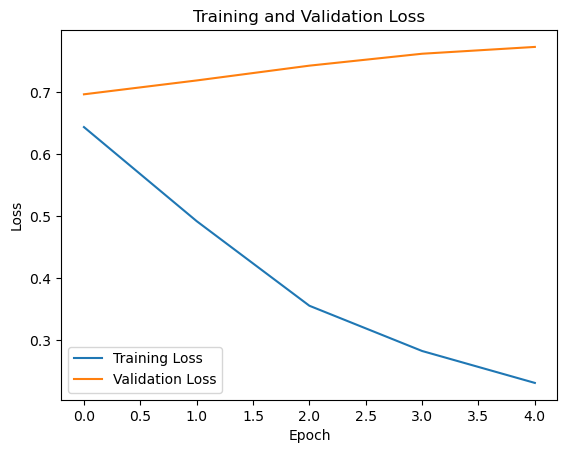

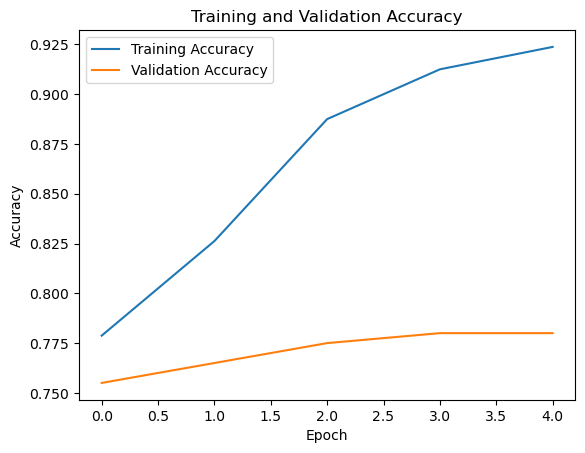

In [13]:
import matplotlib.pyplot as plt
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()
# Plotting training accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()